In [1]:
%load_ext autoreload
%autoreload 2

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from cogformer.simulator.benchmarks.ssms.priors import rdm_priors
from cogformer.simulator.benchmarks.ssms.link_funs import rdm_link_fun

In [4]:
from cogformer.simulator import ModelFamily
from cogformer.simulator.benchmarks import RDM

In [5]:
NUM_ALTERNATIVES = 4
NUM_OBS = 2000

Valid trials: 2000 / 2000
Choice counts: {0: np.int64(489), 1: np.int64(490), 2: np.int64(511), 3: np.int64(510)}


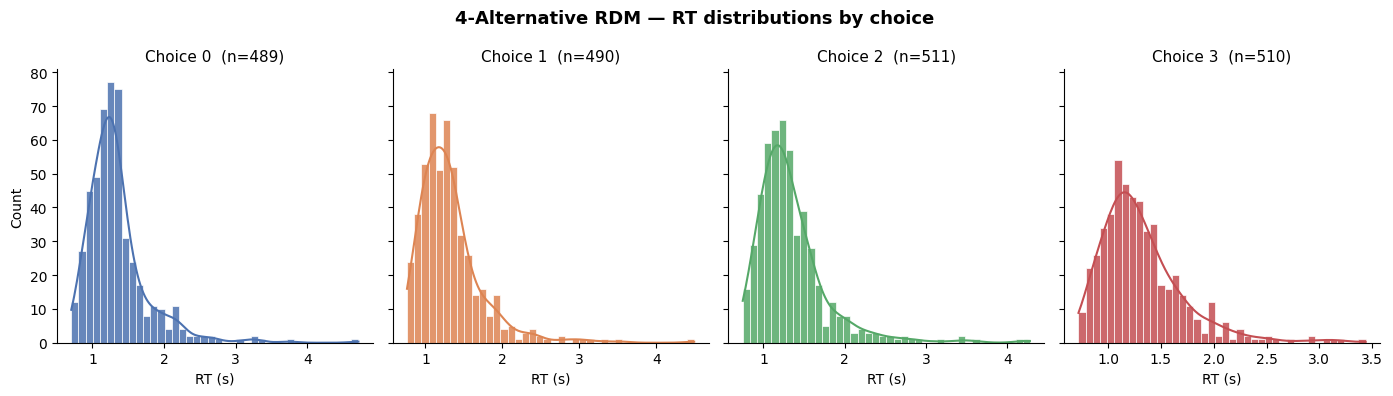

In [10]:
# --- Build ModelFamily ---
rdm = RDM()
family = ModelFamily(
    model=rdm,
    prior_fun=rdm_priors(),
    name="RDM-4alt",
)

# --- Sample with 4-alternative context ---
context = lambda n: RDM.build_context(n, num_alternatives=NUM_ALTERNATIVES)
result = family.sample(
    num_obs=NUM_OBS,
    context=context(NUM_OBS),
    link_fun=rdm_link_fun(),
)

rts     = result["sim_trials"]["rts"].squeeze()       # (NUM_OBS,)
choices = result["sim_trials"]["choices"].squeeze()   # (NUM_OBS,)

# Filter out non-decisions (rt == -1)
valid = rts > 0
rts, choices = rts[valid], choices[valid].astype(int)

print(f"Valid trials: {valid.sum()} / {NUM_OBS}")
print(f"Choice counts: { {i: (choices == i).sum() for i in range(NUM_ALTERNATIVES)} }")

# --- Plot: RT distributions per choice ---
fig, axes = plt.subplots(1, NUM_ALTERNATIVES, figsize=(14, 4), sharey=True)
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

for i, ax in enumerate(axes):
    mask = choices == i
    sns.histplot(rts[mask], bins=40, kde=True, ax=ax, color=colors[i], alpha=0.85, edgecolor="white", linewidth=0.5)
    ax.set_title(f"Choice {i}  (n={mask.sum()})", fontsize=11)
    ax.set_xlabel("RT (s)", fontsize=10)
    if i == 0:
        ax.set_ylabel("Count", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"4-Alternative RDM — RT distributions by choice", fontsize=13, fontweight="bold")
plt.tight_layout()